# Regression with a Deep Neural Network (DNN) using TensorFlow and Keras

This notebook is the TensorFlow/Keras equivalent of the supplied PyTorch notebook. It builds and trains the same **deep feedforward neural network**: two input features, two hidden layers containing 10 neurons each with ReLU activations, and one linear output neuron. The target is the sum of the two input values.

The notebook highlights:
- TensorFlow eager execution
- Computational graphs and automatic differentiation with `tf.GradientTape`
- Building a DNN with Keras
- Training with mean squared error (MSE) and stochastic gradient descent (SGD)

Remove TensorFlow installation if __not__ necessary. 

Let's first import the necessary libraries.

In [1]:
%pip install tensorflow


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## How TensorFlow uses eager execution and automatic differentiation

TensorFlow 2 runs eagerly by default: Python statements and tensor operations execute immediately. To calculate derivatives, TensorFlow provides `tf.GradientTape`.

- Operations executed inside a `GradientTape` context are recorded when they involve watched tensors or trainable variables.
- TensorFlow automatically watches trainable variables accessed inside the tape.
- Calling `tape.gradient(target, sources)` computes derivatives using the chain rule.
- A tape is normally used for one gradient calculation. Use `persistent=True` only when multiple gradient calculations are needed from the same recorded computation.
- Unlike PyTorch's `grad_fn` links, TensorFlow does not expose an equivalent public, user-facing per-tensor graph chain in eager mode. The tape records operations internally.

The next cell is a standalone differentiation demonstration, separate from the neural network training below.

In [3]:
# Eager execution: each statement executes immediately.
x = tf.Variable(2.0, dtype=tf.float32)
print("x:", x.numpy())
print("x is a trainable TensorFlow variable:", x.trainable)

# Record the operations performed inside the tape.
with tf.GradientTape() as tape:
    a = x * 3.0
    b = a + 4.0
    y = b ** 2

print("\nIntermediate/result tensors:")
for name, tensor in [("a = x * 3", a), ("b = a + 4", b), ("y = b ** 2", y)]:
    print(f"{name}: value={tensor.numpy()}, shape={tensor.shape}")

# Backpropagation: dy/dx = 2 * (3*x + 4) * 3.
dy_dx = tape.gradient(y, x)
print("\nGradientTape result:")
print("dy/dx =", dy_dx.numpy())
print("Expected gradient =", 2.0 * (3.0 * x.numpy() + 4.0) * 3.0)

x: 2.0
x is a trainable TensorFlow variable: True

Intermediate/result tensors:
a = x * 3: value=6.0, shape=()
b = a + 4: value=10.0, shape=()
y = b ** 2: value=100.0, shape=()

GradientTape result:
dy/dx = 60.0
Expected gradient = 60.0


## Define the deep feedforward neural network

The `DeepFeedForwardNN` Keras model contains the same layers as the PyTorch model:

1. Fully connected (Dense) layer: `input_dim` to `hidden_dim1`, followed by ReLU.
2. Fully connected (Dense) layer: `hidden_dim1` to `hidden_dim2`, followed by ReLU.
3. Fully connected (Dense) output layer: `hidden_dim2` to `output_dim`, with a linear activation.

For the example, the dimensions are 2 → 10 → 10 → 1.

In [4]:
class DeepFeedForwardNN(tf.keras.Model):
    """Feedforward neural network with two ReLU hidden layers."""

    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim):
        super().__init__()
        self.fc1 = tf.keras.layers.Dense(hidden_dim1, activation="relu", name="hidden_1")
        self.fc2 = tf.keras.layers.Dense(hidden_dim2, activation="relu",
                                          name="hidden_2")
        self.fc3 = tf.keras.layers.Dense(output_dim, activation=None,
                                          name="output")

    def call(self, x, training=False):
        x = self.fc1(x)
        x = self.fc2(x)
        return self.fc3(x)

## Inspect the model parameters and gradient calculation

Keras Dense layers create trainable weights and biases. Once the model has been called with an input, its variables are built and can be inspected.

The following cell uses a separate demonstration model so that this inspection does not alter the model trained in `main()`. A `GradientTape` records the forward pass and loss calculation; `tape.gradient` then calculates gradients for the model's trainable variables.

In [5]:
# Separate demonstration model: it does not affect the model in main().
demo_model = DeepFeedForwardNN(input_dim=2, hidden_dim1=10, hidden_dim2=10, output_dim=1)

demo_input = tf.constant([[1.0, 2.0]], dtype=tf.float32)
demo_target = tf.constant([[3.0]], dtype=tf.float32)

# Call once to build the Keras layer variables.
_ = demo_model(demo_input)

print("Trainable model variables:")
for variable in demo_model.trainable_variables:
    print(f"{variable.name}: trainable={variable.trainable}, shape={tuple(variable.shape)}")

# Forward pass and loss are recorded by GradientTape.
with tf.GradientTape() as tape:
    demo_prediction = demo_model(demo_input, training=True)
    demo_loss = tf.keras.losses.MeanSquaredError()(demo_target, demo_prediction)
    demo_loss = tf.reduce_mean(demo_loss)

print("\nEager execution information:")
print("Input:", demo_input.numpy())
print("Prediction:", demo_prediction.numpy())
print("Loss:", demo_loss.numpy())
print("Prediction is an eager tensor:", tf.executing_eagerly())

# Calculate gradients for every trainable model variable.
demo_gradients = tape.gradient(demo_loss, demo_model.trainable_variables)

print("\nExample parameter gradients:")
for variable, gradient in zip(demo_model.trainable_variables, demo_gradients):
    print(f"{variable.name}: gradient available={gradient is not None}, "
          f"gradient shape={None if gradient is None else tuple(gradient.shape)}")

Trainable model variables:
kernel: trainable=True, shape=(2, 10)
bias: trainable=True, shape=(10,)
kernel: trainable=True, shape=(10, 10)
bias: trainable=True, shape=(10,)
kernel: trainable=True, shape=(10, 1)
bias: trainable=True, shape=(1,)

Eager execution information:
Input: [[1. 2.]]
Prediction: [[0.62620384]]
Loss: 5.6349087
Prediction is an eager tensor: True

Example parameter gradients:
kernel: gradient available=True, gradient shape=(2, 10)
bias: gradient available=True, gradient shape=(10,)
kernel: gradient available=True, gradient shape=(10, 10)
bias: gradient available=True, gradient shape=(10,)
kernel: gradient available=True, gradient shape=(10, 1)
bias: gradient available=True, gradient shape=(1,)


## Train the neural network

The training loop runs for 1,000 epochs. Each epoch:
1. Opens a `GradientTape` context and performs the forward pass.
2. Calculates mean squared error (MSE).
3. Uses the tape to calculate gradients of the loss with respect to trainable model variables.
4. Applies those gradients using the SGD optimiser.

This is the TensorFlow equivalent of the explicit PyTorch forward pass, `loss.backward()`, and `optimizer.step()` sequence. Training progress is printed every 100 epochs, followed by an Epoch vs Loss plot.

In [16]:
def train_model(sample_data, labels, model, loss_fn, optimizer):
    """Train the Keras model using an explicit GradientTape loop."""
    num_epochs = 1200
    epoch_losses = []

    for epoch in range(num_epochs):
        # GradientTape records the forward pass and loss computation.
        with tf.GradientTape() as tape:
            predictions = model(sample_data, training=True)
            loss = loss_fn(labels, predictions)

        # Calculate d(loss)/d(parameter), then update model parameters.
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))

        loss_value = float(loss.numpy())
        epoch_losses.append(loss_value)

        if (epoch + 1) % 100 == 0:
            print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {loss_value:.6f}")

    # Plot Epoch vs Loss.
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, num_epochs + 1), epoch_losses, label="Training loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Epoch vs Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return epoch_losses

## Configure, train, and test the model

The training inputs and labels match the PyTorch notebook. Each target is the sum of the two values in its input row. The model uses MSE loss and SGD with a learning rate of `0.0001`, and is trained for 1,000 epochs.

After training, the model predicts the sums for three unseen input rows. In TensorFlow, simply calling the model for inference does not calculate gradients unless a `GradientTape` is used; `training=False` also puts layers into inference behaviour where relevant (for example, Dropout or Batch Normalization).

Shape of sample_data = (5, 2)
sample_data =
 [[1. 2.]
 [2. 3.]
 [3. 4.]
 [4. 5.]
 [5. 6.]]
Shape of labels = (5, 1)
labels =
 [[ 3.]
 [ 5.]
 [ 7.]
 [ 9.]
 [11.]]
Epoch [100/1200], Loss: 0.142531
Epoch [200/1200], Loss: 0.012389
Epoch [300/1200], Loss: 0.011891
Epoch [400/1200], Loss: 0.011554
Epoch [500/1200], Loss: 0.011226
Epoch [600/1200], Loss: 0.010908
Epoch [700/1200], Loss: 0.010599
Epoch [800/1200], Loss: 0.010299
Epoch [900/1200], Loss: 0.010007
Epoch [1000/1200], Loss: 0.009724
Epoch [1100/1200], Loss: 0.009449
Epoch [1200/1200], Loss: 0.009182


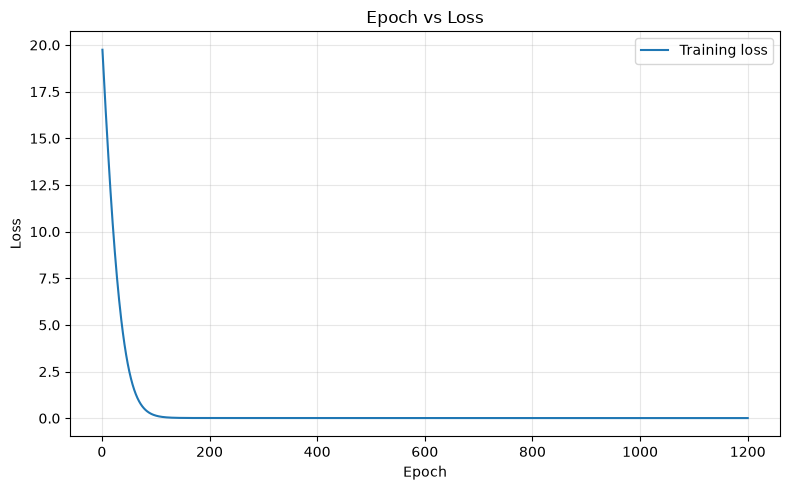

\nTest data:
[[6. 7.]
 [7. 8.]
 [8. 9.]]
\nPredictions for test data:
[[12.843379]
 [14.779106]
 [16.714834]]


In [17]:
def main():
    """Configure, train, and evaluate the deep neural network."""

    # Network dimensions: two inputs, two hidden layers of ten neurons,
    # and one output.
    input_dim = 2
    hidden_dim1 = 10
    hidden_dim2 = 10
    output_dim = 1

    # Sample training data.
    sample_data = tf.constant(
        [[1.0, 2.0], [2.0, 3.0], [3.0, 4.0],
         [4.0, 5.0], [5.0, 6.0]],
        dtype=tf.float32
    )
    print(f"Shape of sample_data = {sample_data.shape}")
    print("sample_data =\n", sample_data.numpy())

    # Ground-truth labels: sum the two input values in each row.
    labels = tf.reduce_sum(sample_data, axis=1, keepdims=True)
    print(f"Shape of labels = {labels.shape}")
    print("labels =\n", labels.numpy())

    # Create the model. Keras builds its variables on the first call.
    model = DeepFeedForwardNN(input_dim, hidden_dim1, hidden_dim2, output_dim)
    _ = model(sample_data)

    # MSE loss and SGD optimiser, matching the PyTorch example.
    loss_fn = tf.keras.losses.MeanSquaredError()
    optimizer = tf.keras.optimizers.SGD(learning_rate=0.0001)

    train_model(sample_data, labels, model, loss_fn, optimizer)

    # Test with new, unseen data.
    test_data = tf.constant(
        [[6.0, 7.0], [7.0, 8.0], [8.0, 9.0]],
        dtype=tf.float32
    )
    test_predictions = model(test_data, training=False)

    print("\\nTest data:")
    print(test_data.numpy())
    print("\\nPredictions for test data:")
    print(test_predictions.numpy())

    return model


if __name__ == "__main__":
    trained_model = main()

## Experiment with the learning rate

Change the SGD learning rate in `main()` and rerun the training cell. For example, try values from `0.1` down to `0.0001`, decreasing by a factor of ten each time.

Observe how the Epoch vs Loss plot changes and how closely the predictions match the expected sums (13, 15, and 17). A learning rate that is too large may make training unstable or cause the loss to increase; one that is too small may make learning very slow. The best value is one that reduces the loss reliably without unnecessary training time.

**Note:** Neural-network weights are randomly initialised, so exact loss values and predictions can vary between runs. TensorFlow and PyTorch may also produce different numerical results because their default initialisations and random-number generators differ, even though the network architecture, data, loss, optimiser type, learning rate, and number of epochs are matched.